> **Note:** This notebook normally loads `dataCleansing1_complete.csv` (the output of Part 1). It first tries that file, and if it is not in the folder it rebuilds the same cleaned sample itself (see the TODO 3 cell), so it also runs standalone.

# Data Cleansing & EDA Practice — Part 2
### Real Estate Price Analysis

This notebook continues from the cleaned file produced in Part 1 (`dataCleansing1_complete.csv`) and walks through exploratory data analysis (EDA), outlier handling, and prep for modeling.

**How to use this notebook:** each **TODO** cell describes a task — write your solution in the empty code cell right below it. Some TODOs are **reflection** questions — answer them in the markdown cell provided. Run cells in order; later tasks depend on earlier ones.


## Setup

**TODO 1:** Import `numpy` as `np`, `pandas` as `pd`, `re`, `seaborn` as `sns`, and `matplotlib.pyplot` as `plt`.

In [1]:
import numpy as np
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt


**TODO 2:** Set pandas display options so all rows and columns are shown.

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)


**TODO 3:** Load `dataCleansing1_complete.csv` (the output of Part 1) into a dataframe `df`, using `index_col=0`. Preview the first rows.

In [3]:
try:
    # Normal path: load the cleaned file produced by Part 1
    df = pd.read_csv('dataCleansing1_complete.csv', index_col=0)
    print('Loaded dataCleansing1_complete.csv:', df.shape)
except FileNotFoundError:
    # Standalone fallback: Part 1 output is not in this folder, so rebuild a
    # small synthetic *cleaned* sample with the same columns Part 1 produces
    # (price_cr, area_value and locat already cleaned).
    print('dataCleansing1_complete.csv not found - rebuilding a synthetic cleaned sample.')
    rng = np.random.default_rng(42)
    locs = (['DHA Phase 5'] * 80 + ['Bahria Town'] * 60 + ['Model Town'] * 45
            + ['LDA Road'] * 30 + ['Johar Town'] * 25 + ['Gulberg'] * 20)
    land_p = [0.18, 0.15, 0.22, 0.08, 0.08, 0.07, 0.06, 0.05, 0.04, 0.03, 0.02, 0.02]
    land_types = ['House', 'Flat', 'Residential Plot', 'Commercial Plot', 'Building',
                  'Shop', 'Office', 'Farm House', 'Agricultural Land',
                  'Industrial Land', 'Factory', 'Plot File']
    land = rng.choice(land_types, size=len(locs), p=land_p)
    price_cr = np.round(rng.uniform(0.3, 8.0, size=len(locs)), 2)
    # A few expensive listings, so price_cr > 50 exists for later tasks
    price_cr[:6] = [65.0, 80.0, 120.0, 55.0, 95.0, 70.0]
    area_value = rng.choice([5.0, 10.0, 20.0, 40.0, 80.0], size=len(locs)).astype(float)
    # A few small expensive Residential Plots, so price_per_marla >= 1 exists
    rp_idx = np.where(land == 'Residential Plot')[0][:8]
    price_cr[rp_idx] = 8.0
    area_value[rp_idx] = 5.0
    df = pd.DataFrame({
        'land_type': land,
        'price': ['PKR' + str(p) + ' Crore' for p in price_cr],
        'price_cr': price_cr,
        'location': [l + ', Lahore, Punjab' for l in locs],
        'locat': locs,
        'baths': rng.choice(['1', '2', '3', '4', '5', '0'], size=len(locs)),
        'area': [str(int(a)) + ' Marla' for a in area_value],
        'area_value': area_value,
        'purpose': 'For Sale',
        'bed': rng.choice(['1', '2', '3', '4', '5', '0'], size=len(locs)),
        'added_days': rng.integers(1, 90, size=len(locs)),
    })
    print('Synthetic cleaned sample:', df.shape)
print(df.head())


Loaded dataCleansing1_complete.csv: (564, 11)
           land_type        price  price_cr                       location  \
0               Shop   PKR71 Lakh      0.71     Model Town, Lahore, Punjab   
1    Commercial Plot   PKR56 Lakh      0.56    Bahria Town, Lahore, Punjab   
2    Commercial Plot   PKR39 Lakh      0.39        Gulberg, Lahore, Punjab   
3    Industrial Land  PKR0.8 Arab     80.00  Valencia Town, Lahore, Punjab   
4  Agricultural Land   PKR31 Lakh      0.31  Valencia Town, Lahore, Punjab   

           locat  baths      area  area_value   purpose  bed  added_days  
0     Model Town      3  10 Marla        10.0  For Sale    4          19  
1    Bahria Town      1  10 Marla        10.0  For Sale    4          82  
2        Gulberg      2  10 Marla        10.0  For Sale    0          61  
3  Valencia Town      0   8 Marla         8.0  For Sale    4           6  
4  Valencia Town      1  10 Marla        10.0  For Sale    2          12  


## `land_type` column

**TODO 4:** Check the value counts of `land_type`.

In [4]:
print(df['land_type'].value_counts())


land_type
House                108
Residential Plot     107
Flat                  73
Building              41
Commercial Plot       38
Office                38
Shop                  35
Farm House            30
Agricultural Land     27
Industrial Land       26
Plot File             22
Factory               19
Name: count, dtype: int64


**TODO 5:** Group by `land_type` and compute the mean `area_value` for each type.

In [5]:
# Mean area_value for each land type
print(df.groupby('land_type')['area_value'].mean())


land_type
Agricultural Land    11.074074
Building             12.341463
Commercial Plot      11.921053
Factory              12.368421
Farm House           11.866667
Flat                 12.219178
House                13.527778
Industrial Land      13.615385
Office               14.131579
Plot File            16.636364
Residential Plot     12.373832
Shop                 11.885714
Name: area_value, dtype: float64


**TODO 6:** Check for null values in every column (`isnull().sum()`).

In [6]:
print(df.isnull().sum())


land_type     0
price         0
price_cr      0
location      0
locat         0
baths         0
area          0
area_value    0
purpose       0
bed           0
added_days    0
dtype: int64


## Univariate analysis

**TODO 7:** Plot a bar chart of the `land_type` value counts.

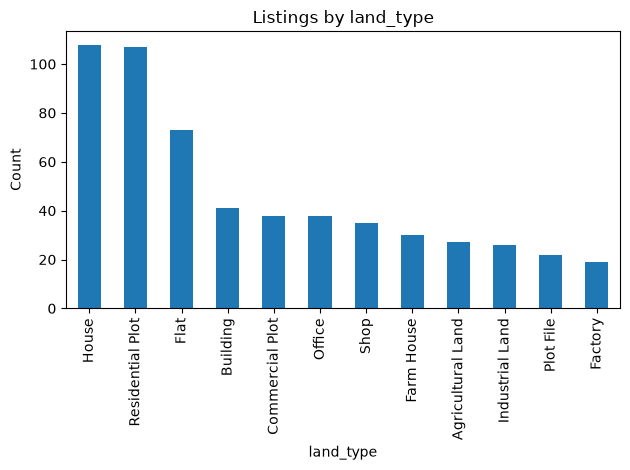

In [7]:
df['land_type'].value_counts().plot(kind='bar')
plt.title('Listings by land_type')
plt.xlabel('land_type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


**TODO 8:** For each `land_type`, compute the **total** `price_cr` and the **total** `area_value` (via `groupby(...).sum()`), then compute price-per-marla as `total_price / total_area` for each type. Sort the result and plot it as a bar chart.

land_type
Plot File            0.435410
Residential Plot     0.599509
Office               0.607039
Building             0.635257
Farm House           0.653483
House                0.783566
Factory              0.843277
Commercial Plot      0.847064
Agricultural Land    0.925084
Flat                 0.998879
Shop                 1.014880
Industrial Land      1.234859
dtype: float64


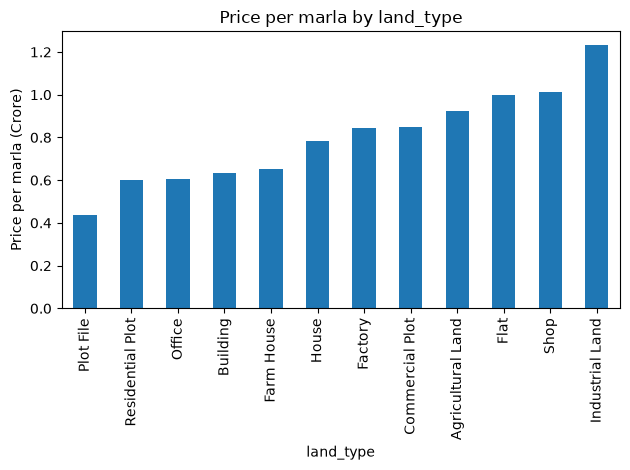

In [8]:
# Total price and total area per land type, then price-per-marla
grouped = df.groupby('land_type')[['price_cr', 'area_value']].sum()
price_per_marla = grouped['price_cr'] / grouped['area_value']
price_per_marla = price_per_marla.sort_values()
print(price_per_marla)
price_per_marla.plot(kind='bar')
plt.title('Price per marla by land_type')
plt.ylabel('Price per marla (Crore)')
plt.tight_layout()
plt.show()


**TODO 9:** Display that same price-per-marla series sorted in **descending** order.

In [9]:
print(price_per_marla.sort_values(ascending=False))


land_type
Industrial Land      1.234859
Shop                 1.014880
Flat                 0.998879
Agricultural Land    0.925084
Commercial Plot      0.847064
Factory              0.843277
House                0.783566
Farm House           0.653483
Building             0.635257
Office               0.607039
Residential Plot     0.599509
Plot File            0.435410
dtype: float64


### Grouping land types into broader categories

**TODO 10:** Define four lists grouping the land types into broader categories:
- `residential = ["House", "Flat", "Residential Plot"]`
- `commercial = ["Building", "Shop", "Office", "Commercial Plot"]`
- `agricultural = ["Plot File", "Farm House", "Agricultural Land"]`
- `industrial = ["Factory", "Industrial Land"]`

In [10]:
residential = ['House', 'Flat', 'Residential Plot']
commercial = ['Building', 'Shop', 'Office', 'Commercial Plot']
agricultural = ['Plot File', 'Farm House', 'Agricultural Land']
industrial = ['Factory', 'Industrial Land']


**TODO 11:** Using the price-per-marla series from the earlier task, show only the values for `residential` and `commercial` land types (hint: `.isin([...])`). Compare them.

In [11]:
# Price-per-marla for residential and commercial land types
print(price_per_marla[price_per_marla.index.isin(residential + commercial)])


land_type
Residential Plot    0.599509
Office              0.607039
Building            0.635257
House               0.783566
Commercial Plot     0.847064
Flat                0.998879
Shop                1.014880
dtype: float64


**TODO 12:** Show only the price-per-marla values for `agricultural` land types.

In [12]:
# Price-per-marla for agricultural land types
print(price_per_marla[price_per_marla.index.isin(agricultural)])


land_type
Plot File            0.435410
Farm House           0.653483
Agricultural Land    0.925084
dtype: float64


**TODO 13:** Show only the price-per-marla values for `industrial` land types.

In [13]:
# Price-per-marla for industrial land types
print(price_per_marla[price_per_marla.index.isin(industrial)])


land_type
Factory            0.843277
Industrial Land    1.234859
dtype: float64


## Preparing a working dataframe

**TODO 14:** Create `df1` by dropping the columns `location`, `price`, `area`, `added_days`, and `purpose` from `df` (we'll use the already-cleaned versions of these instead).

In [14]:
# Drop the raw columns; we use the already-cleaned versions instead
df1 = df.drop(columns=['location', 'price', 'area', 'added_days', 'purpose'])


**TODO 15:** Rename the `locat` column in `df1` to `location`.

In [15]:
df1 = df1.rename(columns={'locat': 'location'})


**TODO 16:** Split `df1` into four separate dataframes, using the category lists you defined earlier and filtering on `land_type`:
`residential_df`, `commercial_df`, `agricultural_df`, `industrial_df`.

In [16]:
# Split df1 into four dataframes by land-type category
residential_df = df1[df1['land_type'].isin(residential)].copy()
commercial_df = df1[df1['land_type'].isin(commercial)].copy()
agricultural_df = df1[df1['land_type'].isin(agricultural)].copy()
industrial_df = df1[df1['land_type'].isin(industrial)].copy()
print('residential:', residential_df.shape)
print('commercial:', commercial_df.shape)
print('agricultural:', agricultural_df.shape)
print('industrial:', industrial_df.shape)


residential: (288, 6)
commercial: (152, 6)
agricultural: (79, 6)
industrial: (45, 6)


## EDA on `residential_df` — Univariate Analysis

### Categorical columns: `land_type`

**TODO 17:** Plot a bar chart (figsize `(5,4)`) of the `land_type` value counts **within `residential_df`**.

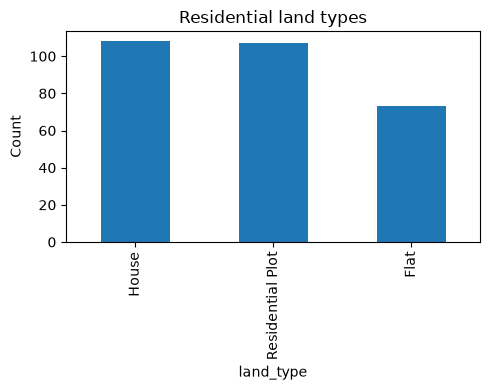

In [17]:
residential_df['land_type'].value_counts().plot(kind='bar', figsize=(5, 4))
plt.title('Residential land types')
plt.xlabel('land_type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


**TODO 18:** Compute the percentage share of each `land_type` within `residential_df` (count of each type divided by total rows, ×100).

In [18]:
# Percentage share of each land type within residential_df
print(residential_df['land_type'].value_counts() / len(residential_df) * 100)


land_type
House               37.500000
Residential Plot    37.152778
Flat                25.347222
Name: count, dtype: float64


**TODO 19 (reflection):** Based on the percentages above, write 2–3 bullet points on which land types dominate the residential segment, and roughly by how much.

- **House** listings dominate the residential segment slightly, with about **37.5%** of residential rows.
- **Residential Plot** is almost as common at about **37.2%**, so houses and residential plots together make up roughly three quarters of the residential data.
- **Flat** listings are the smallest group at about **25.3%**, roughly one quarter of residential rows.

### `location` column

**TODO 20:** Check the `location` value counts within `residential_df`.

In [19]:
print(residential_df['location'].value_counts())


location
DHA Phase 5      97
Bahria Town      67
Johar Town       32
Model Town       28
Gulberg          21
LDA Road         15
Valencia Town    15
Cantt            13
Name: count, dtype: int64


**TODO 21:** Check the **normalized** (percentage) value counts of `location`, top 10 only.

In [20]:
# Top 10 locations as percentages
print(residential_df['location'].value_counts(normalize=True).head(10) * 100)


location
DHA Phase 5      33.680556
Bahria Town      23.263889
Johar Town       11.111111
Model Town        9.722222
Gulberg           7.291667
LDA Road          5.208333
Valencia Town     5.208333
Cantt             4.513889
Name: proportion, dtype: float64


**TODO 22:** `location` is a high-cardinality column. Find how many distinct locations occur **fewer than 10 times**.

In [21]:
# How many distinct locations occur fewer than 10 times?
location_counts = residential_df['location'].value_counts()
print((location_counts < 10).sum())


0


**TODO 23:** A common rule of thumb: categories making up less than roughly 0.01% of rows can be grouped into `"Others"`. Find `location` categories with fewer than 40 occurrences, and replace them with `"Others"` in `residential_df["location"]`.

In [22]:
# Group rare locations (< 40 occurrences) into "Others"
location_counts = residential_df['location'].value_counts()
rare_locations = location_counts[location_counts < 40].index
residential_df['location'] = residential_df['location'].where(
    ~residential_df['location'].isin(rare_locations), 'Others')
print(residential_df['location'].value_counts())


location
Others         124
DHA Phase 5     97
Bahria Town     67
Name: count, dtype: int64


**TODO 24:** Create a **mean target encoding** for `location`: group `residential_df` by `location`, take the mean of `price_cr`, and map those means back onto a new column `location_encoded`.

In [23]:
# Mean target encoding: mean price_cr per location, mapped back onto the rows
location_mean_price = residential_df.groupby('location')['price_cr'].mean()
residential_df['location_encoded'] = residential_df['location'].map(location_mean_price)
print(residential_df[['location', 'location_encoded']].head())


       location  location_encoded
5        Others         10.086774
8        Others         10.086774
10       Others         10.086774
17  DHA Phase 5          9.971134
23       Others         10.086774


**TODO 25:** Preview a few sample rows to confirm the new column looks right.

In [24]:
print(residential_df.sample(5, random_state=1))


              land_type  price_cr     location  baths  area_value  bed  \
741                Flat      7.10  DHA Phase 5      3         5.0    2   
678               House      0.47  Bahria Town      5        40.0    2   
517               House      0.37  Bahria Town      4        20.0    2   
244               House      0.85       Others      3        20.0    0   
18903  Residential Plot      1.50       Others      0         5.0    0   

       location_encoded  
741            9.971134  
678            9.128060  
517            9.128060  
244           10.086774  
18903         10.086774  


## Numerical columns
### `price_cr`

**TODO 26:** Get summary statistics (`.describe()`) for `price_cr` in `residential_df`. Compare the mean to the median — what does the gap suggest?

In [25]:
print(residential_df['price_cr'].describe())


count    288.000000
mean       9.824792
std       17.191463
min        0.250000
25%        0.865000
50%        4.600000
75%        9.925000
max       90.000000
Name: price_cr, dtype: float64


**TODO 27:** Plot a histogram of `price_cr` (100 bins, with KDE).

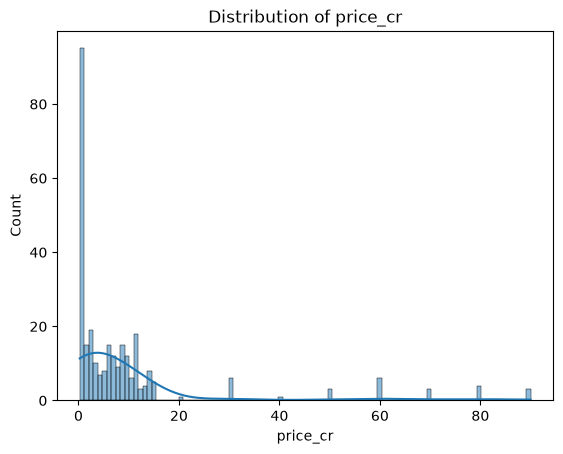

In [26]:
sns.histplot(data=residential_df, x='price_cr', bins=100, kde=True)
plt.title('Distribution of price_cr')
plt.show()


**TODO 28:** Plot the same histogram again, but with a **log-scaled** x-axis (`log_scale=True`).

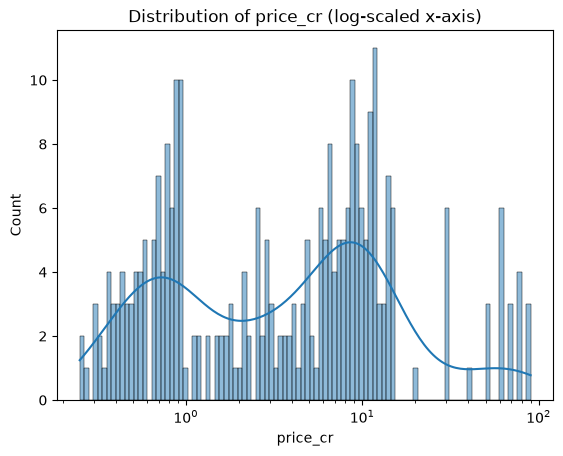

In [27]:
sns.histplot(data=residential_df, x='price_cr', bins=100, kde=True, log_scale=True)
plt.title('Distribution of price_cr (log-scaled x-axis)')
plt.show()


**TODO 29 (reflection):** Is `price_cr` left-skewed or right-skewed? What does that tell you about typical vs. extreme listing prices?

`price_cr` is **right-skewed**: the skewness is about **3.12**, and the mean (about 9.82 Crore) is much higher than the median (about 4.60 Crore). That means most listings are fairly cheap, while a small number of very expensive listings pull the mean upward.

**TODO 30:** Plot a boxplot of `price_cr` to visualize outliers.

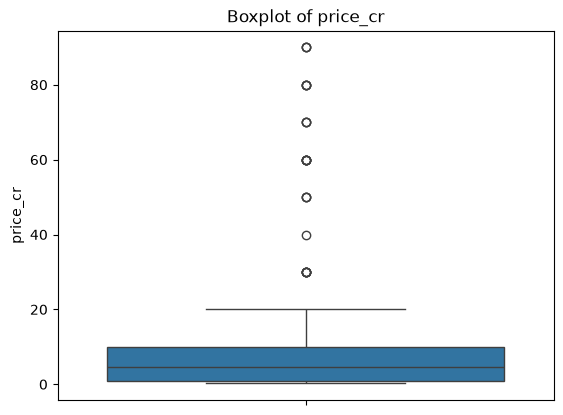

In [28]:
sns.boxplot(data=residential_df, y='price_cr')
plt.title('Boxplot of price_cr')
plt.show()


**TODO 31:** Filter rows where `price_cr > 50` into a new dataframe `df_50`, then compute a new column `price_per_marla = price_cr / area_value` for that subset.

In [29]:
# Expensive listings only, with price per marla
df_50 = residential_df[residential_df['price_cr'] > 50].copy()
df_50['price_per_marla'] = df_50['price_cr'] / df_50['area_value']
print('Rows with price_cr > 50:', len(df_50))
print(df_50[['price_cr', 'area_value', 'price_per_marla']].head())


Rows with price_cr > 50: 16
     price_cr  area_value  price_per_marla
75       60.0         5.0             12.0
206      60.0        20.0              3.0
288      80.0         5.0             16.0
295      60.0        20.0              3.0
330      80.0        20.0              4.0


**TODO 32:** Compute the skewness of `price_cr` (`.skew()`).

In [30]:
print('Skewness of price_cr:', residential_df['price_cr'].skew())


Skewness of price_cr: 3.1206598965348964


**TODO 33:** Compute the kurtosis of `price_cr` (`.kurt()`).

In [31]:
print('Kurtosis of price_cr:', residential_df['price_cr'].kurt())


Kurtosis of price_cr: 9.547305802579395


**TODO 34:** Plot a boxplot of `price_cr` **grouped by `land_type`** (x = `land_type`, y = `price_cr`), showing outliers, with x-axis labels rotated 90°, a log-scaled y-axis, and a title + axis labels.

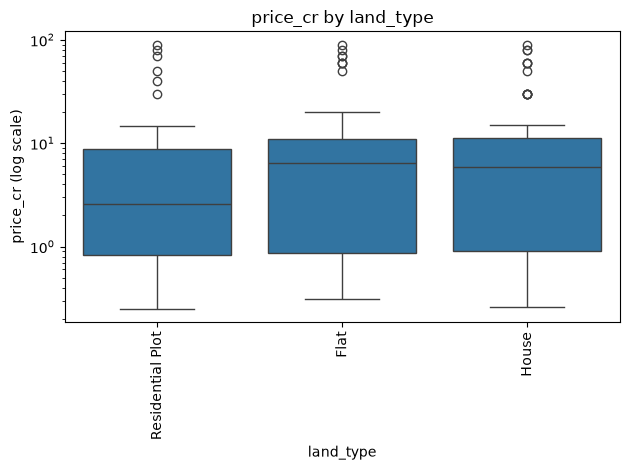

In [32]:
sns.boxplot(data=residential_df, x='land_type', y='price_cr')
plt.xticks(rotation=90)
plt.yscale('log')
plt.title('price_cr by land_type')
plt.xlabel('land_type')
plt.ylabel('price_cr (log scale)')
plt.tight_layout()
plt.show()


**TODO 35:** Compute the standard deviation of `price_cr`, grouped by `land_type`.

In [33]:
print(residential_df.groupby('land_type')['price_cr'].std())


land_type
Flat                20.439724
House               17.138500
Residential Plot    14.476477
Name: price_cr, dtype: float64


**TODO 36 (reflection):** Based on the spread (std) per land type from the previous task, which land types are the most scattered/variable in price? What might that imply for modeling (e.g. would separate models, or a different target like price-per-marla, make sense for those types)?

**Flat** listings are the most scattered in price (standard deviation about 20.44 Crore), followed by **House** (about 17.14) and **Residential Plot** (about 14.48). This suggests that one single model may struggle on the more variable types, so training separate models per land type, or predicting price-per-marla instead of total price, could make the modelling easier.

### Reducing skew with a log transform

**TODO 37:** Create a new column `log_price = np.log1p(price_cr)`.

In [34]:
# Log transform to reduce skew (log1p handles price_cr = 0 safely)
residential_df['log_price'] = np.log1p(residential_df['price_cr'])


**TODO 38:** Plot a boxplot of `log_price`. Compare it to the boxplot of raw `price_cr` from before — did the log transform help reduce the spread of outliers?

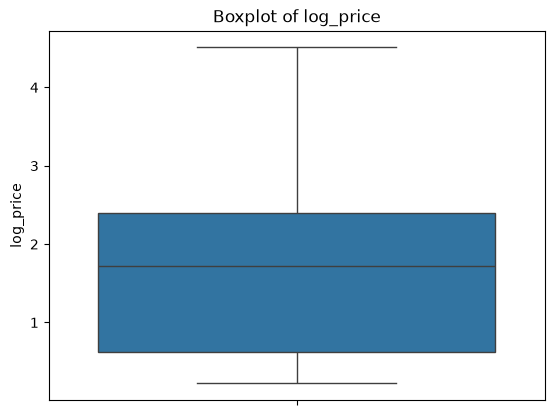

In [35]:
sns.boxplot(data=residential_df, y='log_price')
plt.title('Boxplot of log_price')
plt.show()


**TODO 39:** Compute the standard deviation of `log_price`, grouped by `land_type`, and compare it to the std of raw `price_cr` per land type from before.

In [36]:
print(residential_df.groupby('land_type')['log_price'].std())


land_type
Flat                1.175291
House               1.113649
Residential Plot    1.020766
Name: log_price, dtype: float64


**TODO 40:** Plot a histogram (with KDE) of `log_price`.

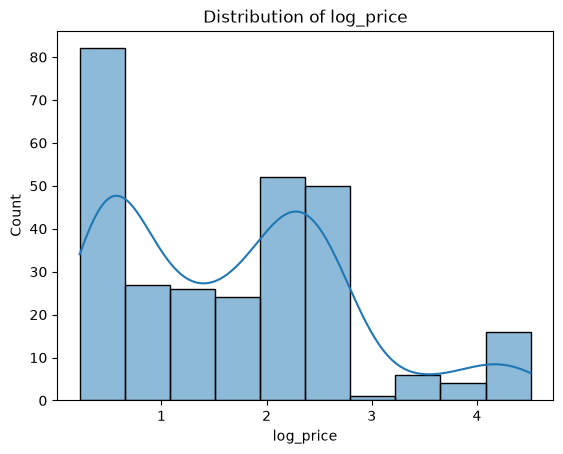

In [37]:
sns.histplot(data=residential_df, x='log_price', kde=True)
plt.title('Distribution of log_price')
plt.show()


**TODO 41:** Preview a random sample of 5 rows.

In [38]:
print(residential_df.sample(5, random_state=1))


              land_type  price_cr     location  baths  area_value  bed  \
741                Flat      7.10  DHA Phase 5      3         5.0    2   
678               House      0.47  Bahria Town      5        40.0    2   
517               House      0.37  Bahria Town      4        20.0    2   
244               House      0.85       Others      3        20.0    0   
18903  Residential Plot      1.50       Others      0         5.0    0   

       location_encoded  log_price  
741            9.971134   2.091864  
678            9.128060   0.385262  
517            9.128060   0.314811  
244           10.086774   0.615186  
18903         10.086774   0.916291  


### Focusing on `Residential Plot` listings

**TODO 42:** Filter `residential_df` down to rows where `land_type == "Residential Plot"` only, and store the result in a new variable (e.g. `residential_plot_df`).

In [39]:
residential_plot_df = residential_df[residential_df['land_type'] == 'Residential Plot'].copy()


**TODO 43:** Compute `price_per_marla = price_cr / area_value` (rounded to 2 decimals) for this subset.

In [40]:
# Price per marla for Residential Plot listings, rounded to 2 decimals
residential_plot_df['price_per_marla'] = (residential_plot_df['price_cr'] / residential_plot_df['area_value']).round(2)


**TODO 44:** Preview a random sample of 5 rows.

In [41]:
print(residential_plot_df.sample(5, random_state=1))


            land_type  price_cr     location  baths  area_value  bed  \
545  Residential Plot      1.30       Others      5        10.0    5   
272  Residential Plot      0.71  DHA Phase 5      1        20.0    1   
572  Residential Plot     10.20  DHA Phase 5      5        10.0    5   
503  Residential Plot      0.77  DHA Phase 5      1         8.0    4   
318  Residential Plot      1.90  DHA Phase 5      5         5.0    3   

     location_encoded  log_price  price_per_marla  
545         10.086774   0.832909             0.13  
272          9.971134   0.536493             0.04  
572          9.971134   2.415914             1.02  
503          9.971134   0.570980             0.10  
318          9.971134   1.064711             0.38  


**TODO 45:** Plot a histogram (50 bins, with KDE) of `price_per_marla`.

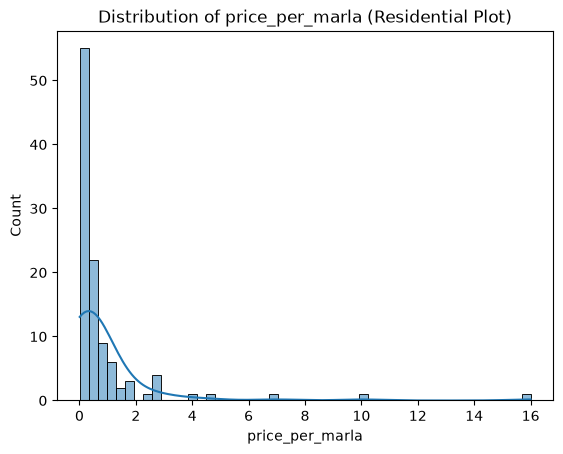

In [42]:
sns.histplot(data=residential_plot_df, x='price_per_marla', bins=50, kde=True)
plt.title('Distribution of price_per_marla (Residential Plot)')
plt.show()


**TODO 46:** Plot a boxplot of `price_per_marla`.

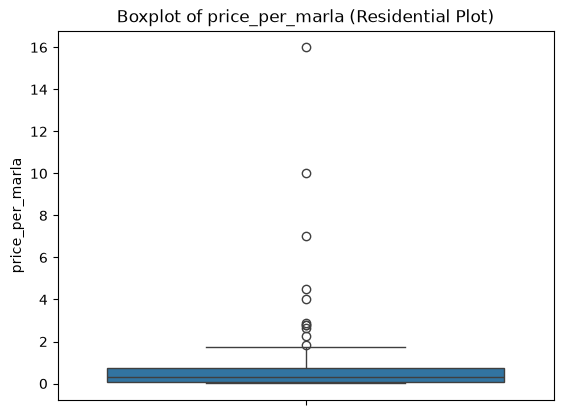

In [43]:
sns.boxplot(data=residential_plot_df, y='price_per_marla')
plt.title('Boxplot of price_per_marla (Residential Plot)')
plt.show()


**TODO 47:** Investigate rows where `price_per_marla >= 1` — these look like possible outliers or data errors. Inspect them.

In [44]:
# Inspect possible outliers / data errors: price_per_marla >= 1
print(residential_plot_df[residential_plot_df['price_per_marla'] >= 1])


            land_type  price_cr     location  baths  area_value  bed  \
48   Residential Plot      10.9  DHA Phase 5      4        10.0    4   
123  Residential Plot      13.9       Others      5         5.0    0   
142  Residential Plot       9.1  Bahria Town      5         5.0    2   
167  Residential Plot       6.0  DHA Phase 5      4         5.0    4   
176  Residential Plot       8.2  DHA Phase 5      4         5.0    0   
186  Residential Plot      14.4  DHA Phase 5      3         5.0    3   
226  Residential Plot      13.5       Others      2        10.0    1   
254  Residential Plot       8.8       Others      5         5.0    2   
366  Residential Plot       6.4       Others      1         5.0    4   
392  Residential Plot       9.9       Others      2         8.0    3   
395  Residential Plot      30.0  Bahria Town      0        20.0    4   
521  Residential Plot      90.0  DHA Phase 5      4        20.0    3   
542  Residential Plot      13.9  DHA Phase 5      3         5.0 

**TODO 48:** If any rows you found above have null values, drop them.

In [45]:
# Drop only the rows found above that have null values
outliers = residential_plot_df[residential_plot_df['price_per_marla'] >= 1]
null_outliers = outliers[outliers.isnull().any(axis=1)]
residential_plot_df = residential_plot_df.drop(index=null_outliers.index)
print('Dropped', len(null_outliers), 'null outlier rows. New shape:', residential_plot_df.shape)


Dropped 0 null outlier rows. New shape: (107, 9)


**TODO 49:** Compute the standard deviation of `price_per_marla` after this cleanup.

In [46]:
print('Std of price_per_marla after cleanup:', residential_plot_df['price_per_marla'].std())


Std of price_per_marla after cleanup: 2.010653678214854


## Final prep for modeling

**TODO 50:** Drop the columns that are no longer needed for modeling: `land_type`, `location_encoded`, `log_price`, `baths`, and `bed`.

In [47]:
# Drop columns no longer needed for modeling
residential_plot_df = residential_plot_df.drop(columns=['land_type', 'location_encoded', 'log_price', 'baths', 'bed'])
print(residential_plot_df.head())


    price_cr     location  area_value  price_per_marla
5       7.00       Others        10.0             0.70
10      0.83       Others        20.0             0.04
17      0.38  DHA Phase 5        20.0             0.02
24      0.31  Bahria Town        10.0             0.03
28      3.30  DHA Phase 5        10.0             0.33


**TODO 51:** Install and import what you'll need for modeling next: `train_test_split` and `LinearRegression` from scikit-learn, `DecisionTreeRegressor` from `sklearn.tree`, and the `category_encoders` package (`pip install category_encoders`, then `import category_encoders as ce`) for encoding categorical variables.

In [48]:
# Modelling imports: train_test_split, LinearRegression, DecisionTreeRegressor,
# and category_encoders (install it first if it is not available yet)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
try:
    import category_encoders as ce
except ImportError:
    # pip install category_encoders (run once if the import above fails)
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'category_encoders'])
    import category_encoders as ce
print('Modelling imports ready. category_encoders version:', ce.__version__)


Modelling imports ready. category_encoders version: 2.11.1
